# Internal predictions analysis (SDN internal classifiers)

Analyses the per-layer internal predictions saved by `code/c0/c0_custom_predictions_densenet121.py`
(Shallow-Deep Networks, Kaya et al., ICML 2019). Questions:

1. **Collinearity** — are internal probabilities just noisy copies of the final probability (R²)?
2. **Distributions** — how do internal probabilities differ between correct and incorrect samples?
3. **Disagreement** — how often does each internal head classify differently from the final head,
   and does a per-sample disagreement score predict correctness?
4. **Correctness prediction** — logistic regression on the internal probability vector.

Run the prediction script first; this notebook only reads its CSVs.

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
# MEDMNIST LOADER — run THIS cell instead of the CheXpert load (cells c1 + filter).
# It sets up train/val/ic_cols/ic_names/colors/rcParams exactly as the rest of the
# notebook expects, then jump straight to §1. MedMNIST wasn't attribute-filtered,
# so the C2-population join below should be ~a no-op (matched ≈ all).
# ══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve

DISEASE = "pneumothorax"
C0_DIR  = f"/work3/s251710/thesis_results/C0_medmnist/{DISEASE}"
C2_DATA = f"/work3/s251710/thesis_results/C2_medmnist/{DISEASE}/c2_data.csv"

# MedMNIST uses train/test (no val split); we call the test split `val` downstream.
train = pd.read_csv(f"{C0_DIR}/train_c0_{DISEASE}.csv")
val   = pd.read_csv(f"{C0_DIR}/test_c0_{DISEASE}.csv")

ic_cols  = [c for c in val.columns if c.startswith("prob_") and c != "prob"]
ic_names = [c[len("prob_"):] for c in ic_cols]
assert ic_cols, "No prob_<layer> columns — re-run c0_predict_medmnist.py to add internal classifiers."

# ── Restrict to the C2 CV population (fair comparison to the C2 models) ─────────
c2_paths = set(pd.read_csv(C2_DATA, usecols=["path"])["path"])
n_before = len(train) + len(val)
pool = pd.concat([train, val], ignore_index=True)
pool = pool[pool["path"].isin(c2_paths)].reset_index(drop=True)
missing = len(c2_paths - set(pool["path"]))
print(f"C0 samples (train+test):  {n_before:,}")
print(f"C2 population (c2_data):   {len(c2_paths):,}")
print(f"matched & kept:           {len(pool):,}")
print(f"C2 paths NOT found in C0:  {missing:,}"
      + ("  <-- investigate if >0" if missing else ""))
train = pool
val   = pool

# colors + style used throughout the notebook
C_OK, C_ERR = "#0072B2", "#D55E00"   # Okabe-Ito blue / vermillion (colorblind-safe)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
})
print("internal heads:", ic_names)

C0 samples (train+test):  100,901
C2 population (c2_data):   22,433
matched & kept:           22,433
C2 paths NOT found in C0:  0
internal heads: ['denseblock1', 'transition1', 'denseblock2', 'transition2', 'denseblock3', 'transition3', 'denseblock4']


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve

DISEASE = "pneumothorax"
OUT = f"/work3/s251710/thesis_results/C0_custom/{DISEASE}"

train = pd.read_csv(f"{OUT}/train_c0_{DISEASE}.csv")
val   = pd.read_csv(f"{OUT}/val_c0_{DISEASE}.csv")

In [21]:
# ── Restrict to the C2 CV population for a fair comparison ────────────────────
# The C2 pipeline (code/c2/c2_cv_pipeline_new_split.py) does NOT use all of C0's
# train/val. It reads a single pre-filtered file, c2_data.csv (samples surviving
# the C1-attribute matching), and runs StratifiedKFold over THAT set. To compare
# on the same footing we (1) inner-join the C0 predictions to c2_data.csv on
# `path`, and (2) pool train+val into one frame, exactly like the C2 pipeline.
C2_DATA = f"/work3/s251710/thesis_results/C2_custom/{DISEASE}/c2_data.csv"
c2 = pd.read_csv(C2_DATA, usecols=["path"])
c2_paths = set(c2["path"])

n_before = len(train) + len(val)
pool = pd.concat([train, val], ignore_index=True)
pool = pool[pool["path"].isin(c2_paths)].reset_index(drop=True)

# sanity: how many C2 paths did we recover from the C0 predictions?
missing = len(c2_paths - set(pool["path"]))
print(f"C0 samples (train+val):   {n_before:,}")
print(f"C2 population (c2_data):   {len(c2_paths):,}")
print(f"matched & kept:           {len(pool):,}")
print(f"C2 paths NOT found in C0:  {missing:,}"
      + ("  <-- investigate if >0" if missing else ""))

# All downstream cells use `train` for CV and `val` for single-split plots.
# Keep the whole C2 population as `train` (CV pools it anyway), and mirror it in
# `val` so the descriptive plots also reflect the C2 population, not all of C0.
train = pool
val   = pool

C0 samples (train+val):   75,789
C2 population (c2_data):   27,722
matched & kept:           27,722
C2 paths NOT found in C0:  0


In [22]:
ic_cols = [c for c in val.columns if c.startswith("prob_")]
ic_names = [c[len("prob_"):] for c in ic_cols]
print(f"train {len(train):,} | val {len(val):,}")
print("internal heads:", ic_names)

# correct vs incorrect colors (Okabe-Ito blue/vermillion, colorblind-safe)
C_OK, C_ERR = "#0072B2", "#D55E00"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
})

train 27,722 | val 27,722
internal heads: ['denseblock1', 'transition1', 'denseblock2', 'transition2', 'denseblock3', 'transition3', 'denseblock4']


## 1. Collinearity with the final probability

High R² → the internal head is redundant with the final output; low R² → it carries
signal the final probability does not (whether that signal is *useful* is tested in §3–4).

In [23]:
rows = []
for c, n in zip(ic_cols, ic_names):
    r = val[c].corr(val["prob"])
    rows.append({"head": n, "pearson_r": r, "R2": r ** 2})

# all internal heads jointly -> final probability (OLS)
joint = LinearRegression().fit(val[ic_cols], val["prob"])
rows.append({"head": "ALL heads (joint OLS)", "pearson_r": np.nan,
             "R2": joint.score(val[ic_cols], val["prob"])})

pd.DataFrame(rows).round(3)

,head,pearson_r,R2
0,denseblock1,0.327,0.107
1,transition1,0.383,0.146
2,denseblock2,0.512,0.262
3,transition2,0.597,0.356
4,denseblock3,0.891,0.794
5,transition3,0.939,0.882
6,denseblock4,0.987,0.973
7,ALL heads (joint OLS),NaN,0.978


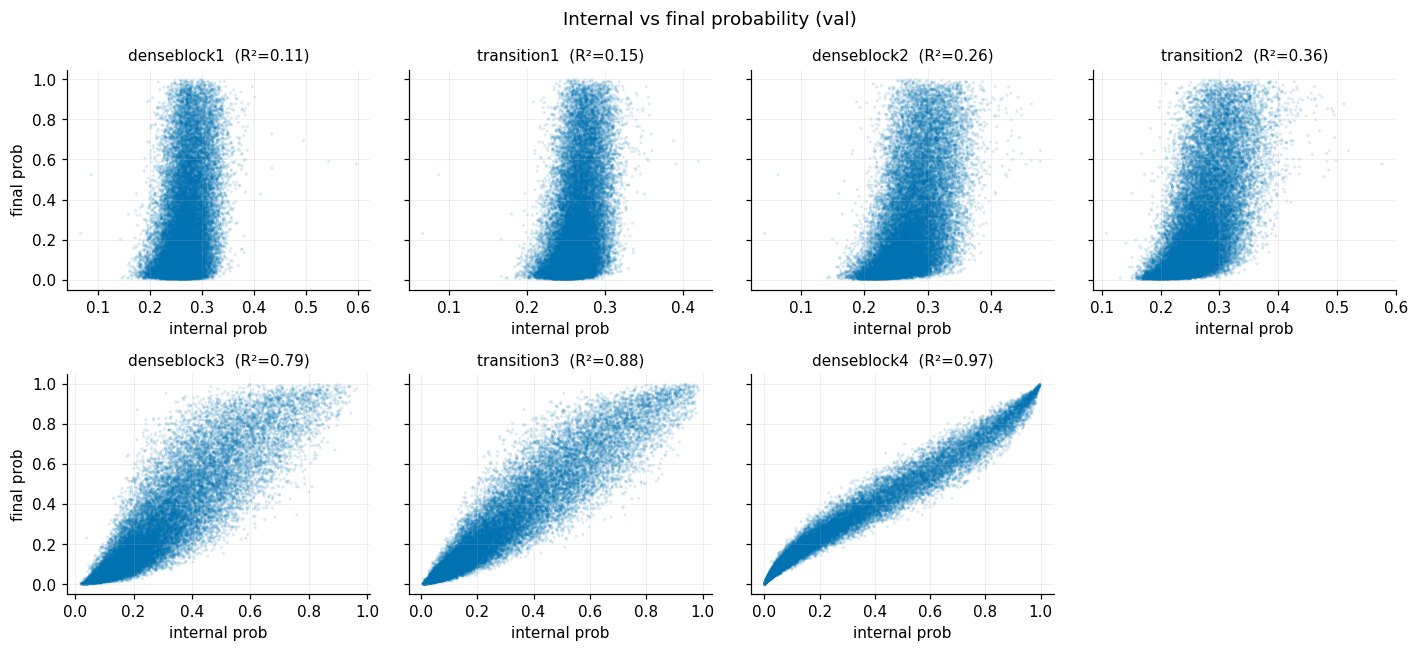

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharey=True)
for ax, c, n in zip(axes.flat, ic_cols, ic_names):
    ax.scatter(val[c], val["prob"], s=4, alpha=0.15, color=C_OK, edgecolors="none")
    ax.set_title(f"{n}  (R²={val[c].corr(val['prob'])**2:.2f})", fontsize=10)
    ax.set_xlabel("internal prob")
for ax in axes[:, 0]:
    ax.set_ylabel("final prob")
for ax in axes.flat[len(ic_cols):]:
    ax.axis("off")
fig.suptitle("Internal vs final probability (val)")
fig.tight_layout()

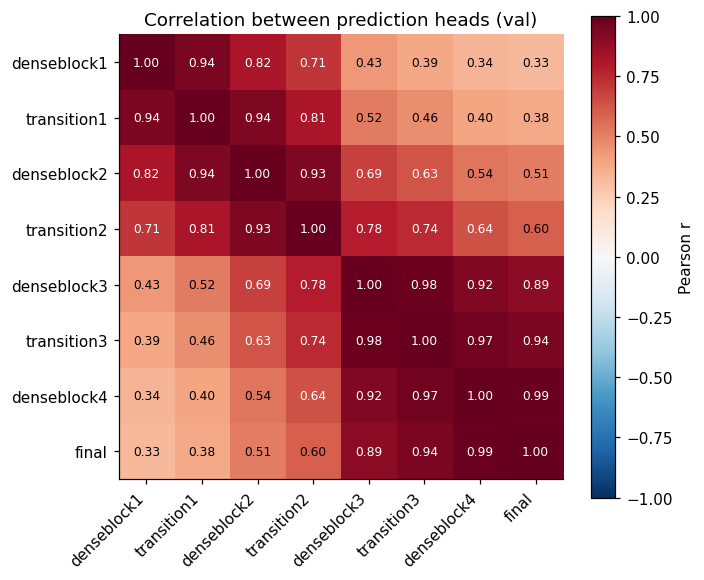

In [25]:
all_cols = ic_cols + ["prob"]
labels = ic_names + ["final"]
corr = val[all_cols].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, label="Pearson r")
ax.set_title("Correlation between prediction heads (val)")
fig.tight_layout()

## 2. Distributions: correct vs incorrect samples

Per head, the internal probability distribution split by whether the **final**
prediction was correct. Separation in the shallow heads = early-layer signal about errors.

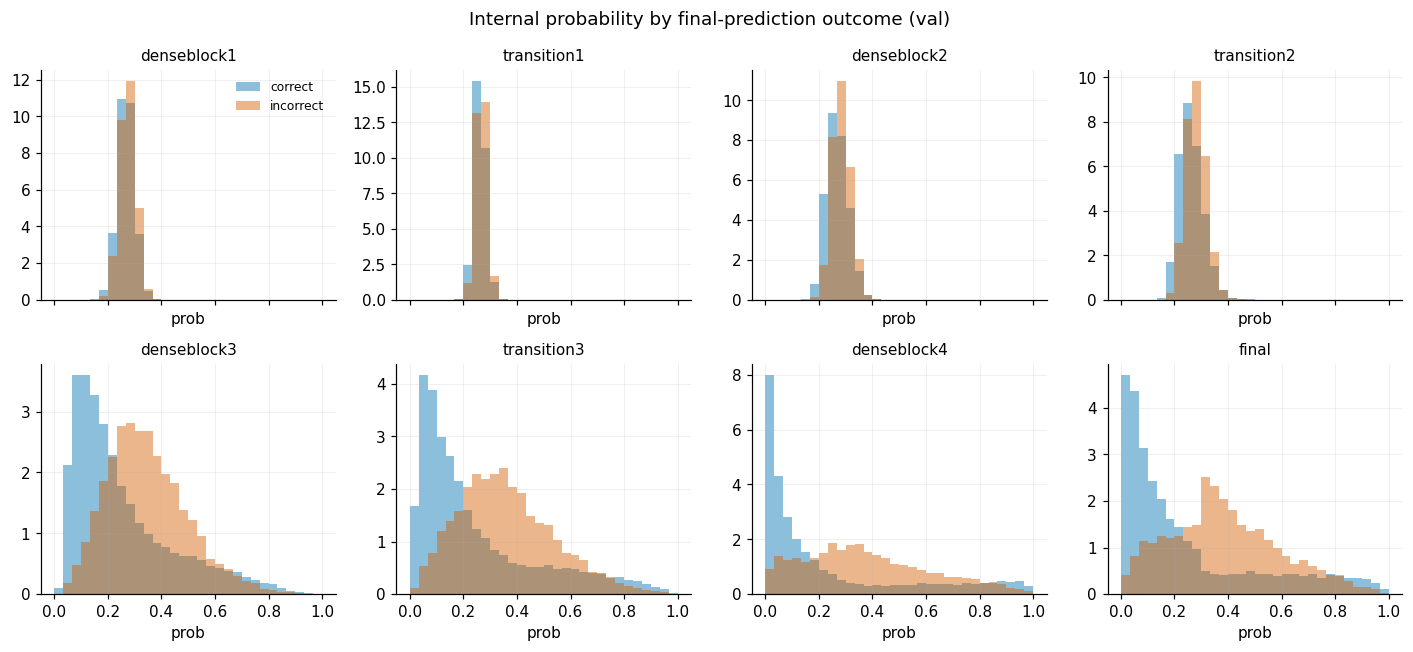

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
bins = np.linspace(0, 1, 31)
for ax, c, n in zip(axes.flat, all_cols, labels):
    for v, color, lbl in [(1, C_OK, "correct"), (0, C_ERR, "incorrect")]:
        ax.hist(val.loc[val["correct"] == v, c], bins=bins, density=True,
                alpha=0.45, color=color, label=lbl)
    ax.set_title(n, fontsize=10)
    ax.set_xlabel("prob")
axes.flat[0].legend(frameon=False, fontsize=8)
fig.suptitle("Internal probability by final-prediction outcome (val)")
fig.tight_layout()

## 3. Disagreement with the final classification

Each head gets its own Youden threshold (fit on **train**), giving a binary internal
prediction per layer. Per head: % agreement with the final prediction. Per sample:
`disagreement` = fraction of heads voting against the final prediction — then test
whether that score predicts errors.

In [27]:
def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return thr[np.argmax(tpr - fpr)]

ic_thr = {c: youden_threshold(train["true"], train[c]) for c in ic_cols}
pred_cols = [f"pred_{n}" for n in ic_names]

for df in (train, val):
    for c, pc in zip(ic_cols, pred_cols):
        df[pc] = (df[c] > ic_thr[c]).astype(int)
    df["n_disagree"] = (df[pred_cols].values != df[["pred"]].values).sum(axis=1)
    df["disagreement"] = df["n_disagree"] / len(ic_cols)

pd.DataFrame({
    "threshold": [ic_thr[c] for c in ic_cols],
    "train agree w/ final (%)": [100 * (train[pc] == train["pred"]).mean() for pc in pred_cols],
    "val agree w/ final (%)":   [100 * (val[pc] == val["pred"]).mean() for pc in pred_cols],
}, index=ic_names).round(2)

,threshold,train agree w/ final (%),val agree w/ final (%)
denseblock1,0.27,61.51,61.51
transition1,0.26,64.93,64.93
denseblock2,0.28,69.58,69.58
transition2,0.27,72.23,72.23
denseblock3,0.28,87.57,87.57
transition3,0.24,89.20,89.20
denseblock4,0.23,95.04,95.04


In [28]:
# ── Confidence & internal-uncertainty features (used by §3b, §4, §5, §6) ──────
# prob_entropy: Bernoulli entropy of the FINAL probability (a confidence measure,
#   max at prob=0.5). ic_entropy: mean Bernoulli entropy ACROSS the internal heads
#   — "how committed were the internal predictions, on average" (high = the network
#   was internally unsure, low = it 'knew' early).
for df in (train, val):
    p = df["prob"].clip(1e-6, 1 - 1e-6)
    df["prob_entropy"] = -(p * np.log(p) + (1 - p) * np.log(1 - p))

    P = df[ic_cols].clip(1e-6, 1 - 1e-6)
    df["ic_entropy"] = (-(P * np.log(P) + (1 - P) * np.log(1 - P))).mean(axis=1)

val AUC, disagreement -> predicting an INCORRECT final prediction: 0.587


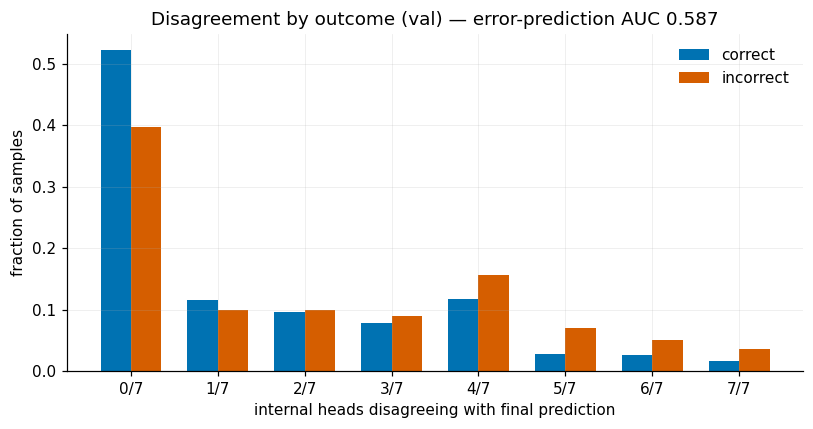

In [29]:
auc_dis = roc_auc_score(1 - val["correct"], val["disagreement"])
print(f"val AUC, disagreement -> predicting an INCORRECT final prediction: {auc_dis:.3f}")

k = len(ic_cols)
levels = np.arange(k + 1)
width = 0.35

fig, ax = plt.subplots(figsize=(7.5, 4))
for v, color, lbl, off in [(1, C_OK, "correct", -0.5), (0, C_ERR, "incorrect", 0.5)]:
    freq = (val.loc[val["correct"] == v, "n_disagree"]
            .value_counts(normalize=True).reindex(levels, fill_value=0))
    ax.bar(levels + off * width, freq.values, width=width, color=color, label=lbl)
ax.set_xticks(levels, [f"{i}/{k}" for i in levels])
ax.set_xlabel("internal heads disagreeing with final prediction")
ax.set_ylabel("fraction of samples")
ax.legend(frameon=False)
ax.set_title(f"Disagreement by outcome (val) — error-prediction AUC {auc_dis:.3f}")
fig.tight_layout()

## 3b. Banded AUROC — do the internals help *near the threshold*?

Global AUROC averages over easy cases and can hide signal that lives only in the
ambiguous zone. Here we bin samples by **distance from the decision threshold**
(`margin` = |final prob − threshold|) and, per band, compute two things:

- **(A) disease AUROC** of each internal head predicting the `true` label — is the
  head still discriminative for the disease when the *final* model is unsure?
- **(B) error-detection AUROC** — does the internal signal flag *incorrect* final
  predictions within that band? (this is the error-detection question, restricted
  to where mistakes actually happen: the low-confidence bands.)

In [30]:
# bin by distance from the decision threshold (val["margin"] already = |prob - thr|)
# quantile edges so each band has a comparable number of samples; band 0 = closest
# to the threshold (most ambiguous), last band = most confident.
N_BANDS = 5
edges = np.quantile(val["margin"], np.linspace(0, 1, N_BANDS + 1))
edges[0], edges[-1] = -np.inf, np.inf
val["conf_band"] = pd.cut(val["margin"], bins=edges, labels=False, include_lowest=True)

def safe_auc(y, s):
    y = np.asarray(y)
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else np.nan

# ── ensure derived signals exist (in case §3 / entropy cells weren't run yet) ──
if "ic_entropy" not in val.columns:
    P = val[ic_cols].clip(1e-6, 1 - 1e-6)
    val["ic_entropy"] = (-(P * np.log(P) + (1 - P) * np.log(1 - P))).mean(axis=1)
if "disagreement" not in val.columns:
    raise KeyError("Run the §3 disagreement cell first — it builds val['disagreement'].")

# ── (A) disease AUROC per internal head, per band ──────────────────────────────
scoreable = ic_cols + ["prob"]
score_names = ic_names + ["final"]
rowsA = []
for b in range(N_BANDS):
    sub = val[val["conf_band"] == b]
    lo, hi = edges[b] if b else 0.0, edges[b + 1]
    r = {"band": f"{b} [{max(lo,0):.2f}–{hi if np.isfinite(hi) else '∞'}]",
         "n": len(sub), "err_rate": 1 - sub["correct"].mean()}
    for c, nm in zip(scoreable, score_names):
        r[nm] = safe_auc(sub["true"], sub[c])
    rowsA.append(r)
tblA = pd.DataFrame(rowsA)
print("(A) disease AUROC by confidence band (band 0 = closest to threshold):")
tblA.round(3)

(A) disease AUROC by confidence band (band 0 = closest to threshold):


,band,n,err_rate,denseblock1,transition1,denseblock2,transition2,denseblock3,transition3,denseblock4,final
0,0 [0.00–0.09260087311267852],5545,0.439,0.541,0.547,0.558,0.572,0.566,0.571,0.592,0.559
1,1 [0.09–0.17494300454854964],5544,0.302,0.561,0.577,0.600,0.620,0.652,0.669,0.682,0.662
2,2 [0.17–0.23708862587809568],5544,0.201,0.615,0.631,0.665,0.690,0.736,0.737,0.743,0.723
3,3 [0.24–0.2838046135380864],5544,0.104,0.655,0.684,0.743,0.771,0.807,0.808,0.821,0.816
4,4 [0.28–∞],5545,0.234,0.668,0.726,0.772,0.782,0.801,0.808,0.818,0.807


(B) error-detection AUROC by confidence band (higher = better flags errors):
 band    n  err_rate  ic_entropy  disagreement
    0 5545     0.439       0.605         0.506
    1 5544     0.302       0.700         0.538
    2 5544     0.201       0.737         0.556
    3 5544     0.104       0.791         0.562
    4 5545     0.234       0.713         0.571


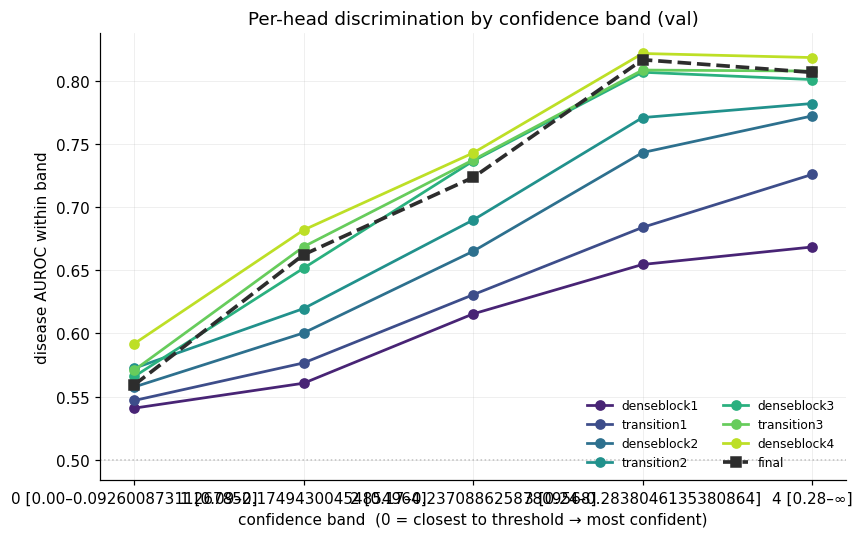

In [31]:
# ── (B) error-detection AUROC per band: does the internal signal flag wrong finals?
# score = ic_entropy and disagreement (built earlier); target = INCORRECT final pred.
err_scores = {"ic_entropy": val["ic_entropy"], "disagreement": val["disagreement"]}
rowsB = []
for b in range(N_BANDS):
    m = val["conf_band"] == b
    y_err = 1 - val.loc[m, "correct"]          # 1 = final prediction was wrong
    r = {"band": b, "n": int(m.sum()), "err_rate": float(y_err.mean())}
    for nm, s in err_scores.items():
        r[nm] = safe_auc(y_err, s[m])
    rowsB.append(r)
tblB = pd.DataFrame(rowsB)
print("(B) error-detection AUROC by confidence band (higher = better flags errors):")
print(tblB.round(3).to_string(index=False))

# ── plot: disease AUROC per head across bands, x = band (ambiguous -> confident) ─
fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(ic_cols)))
for (nm, color) in zip(ic_names, cmap):
    ax.plot(tblA["band"], tblA[nm], marker="o", color=color, lw=1.8, label=nm)
ax.plot(tblA["band"], tblA["final"], marker="s", color="#2D2D2D", lw=2.4,
        ls="--", label="final")
ax.axhline(0.5, color="#BFBFBF", lw=1.0, ls=":")
ax.set_xticks(range(N_BANDS))
ax.set_xlabel("confidence band  (0 = closest to threshold → most confident)")
ax.set_ylabel("disease AUROC within band")
ax.set_title("Per-head discrimination by confidence band (val)")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="lower right")
fig.tight_layout()

## 4. Predicting correctness (logistic regression)


In [32]:
from sklearn.model_selection import cross_val_score

BASELINE = "final prob (baseline)"

feature_sets = {
    # --- baseline: final-layer confidence alone, no internal info ---
    BASELINE:                   ["prob"],
    # --- single internal signals ---
    "prob_entropy":             ["prob_entropy"],
    "ic_entropy":               ["ic_entropy"],
    "disagreement":             ["disagreement"],
    "internal probs":           ic_cols,
    # --- everything internal ---
    "all internal":             ["ic_entropy", "disagreement"] + ic_cols,
}

rows = []
for name, cols in feature_sets.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=1.0))
    # 5-fold CV on train; report the mean AUC across folds
    cv = cross_val_score(clf, train[cols], train["correct"], cv=5, scoring="roc_auc")
    rows.append({"features": name, "n": len(cols), "cv AUC": cv.mean()})

res = pd.DataFrame(rows)
base = res.loc[res["features"] == BASELINE, "cv AUC"].iloc[0]
res["Δ vs baseline"] = res["cv AUC"] - base
res = res.sort_values("cv AUC", ascending=False).reset_index(drop=True)
res.round(3)

,features,n,cv AUC,Δ vs baseline
0,prob_entropy,1,0.776,0.058
1,all internal,9,0.772,0.055
2,ic_entropy,1,0.755,0.037
3,final prob (baseline),1,0.717,0.000
4,internal probs,7,0.690,-0.027
5,disagreement,1,0.587,-0.130


## 5. Is "all internal" a new signal, or just re-encoded confidence?

§1 showed the deep internal probs are ~0.98 collinear with `prob`, so "all internal" could
simply be laundering the final probability/entropy. Two tests:

- **Incremental (nested LR):** does adding "all internal" *on top of* `prob` + entropies raise
  CV AUC? A near-zero gain ⇒ it adds nothing beyond confidence.
- **Residual:** partial out `prob` + entropies from the internal-feature score, then test whether
  the *residual* still predicts correctness. Signal surviving the residual ⇒ genuinely new.

In [14]:
def cv_auc(cols):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=1.0))
    scores = cross_val_score(clf, train[cols], train["correct"], cv=5, scoring="roc_auc")
    return scores.mean(), scores.std()

# --- Check 1: incremental value on top of confidence ---
m_conf, s_conf         = cv_auc(conf_cols)
m_conf_int, s_conf_int = cv_auc(conf_cols + int_cols)

print("Check 1 — incremental value (CV AUC for 'correct')")
print(f"  Final Entropy only        : {m_conf:.3f} ± {s_conf:.3f}")
print(f"  Final Entropy + internals : {m_conf_int:.3f} ± {s_conf_int:.3f}")
print(f"  gain from internals       : {m_conf_int - m_conf:+.3f}")

NameError: name 'conf_cols' is not defined

In [16]:
labels = ["prob\n+ entropy", "+ internal"]
means  = [m_conf, m_conf_int]
stds   = [s_conf, s_conf_int]

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(labels, means, yerr=stds, capsize=5,
              color=[C_OK, C_ERR], edgecolor="black", linewidth=0.5)
ax.set_ylabel("CV AUROC (5-fold)")
ax.set_title("LR: final confidence vs + internal features")   # match your actual reader
ax.set_ylim(0.5, 0.85)                                         # 0.5 = AUROC floor, honest anchor
ax.axhline(0.5, color="grey", lw=0.8, ls=":")                 # chance line
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width()/2, m + 0.02, f"{m:.3f}",
            ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.show()

NameError: name 'm_conf' is not defined

In [33]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import cross_val_score, cross_val_predict

conf_cols = ["prob","prob_entropy"]
int_cols  = ic_cols + ["disagreement", "ic_entropy"]   # the internal-only features

def cv_auc(cols):
    # no StandardScaler: trees are scale-invariant
    scores = cross_val_score(rf_clf(), train[cols], train["correct"],
                             cv=5, scoring="roc_auc")
    return scores.mean(), scores.std()

# --- Check 1: incremental value on top of confidence ---
m_conf, s_conf         = cv_auc(conf_cols)
m_conf_int, s_conf_int = cv_auc(conf_cols + int_cols)

print("Check 1 (RF) — incremental value (CV AUC for 'correct')")
print(f"  Final Entropy only        : {m_conf:.3f} ± {s_conf:.3f}")
print(f"  Final Entropy + internals : {m_conf_int:.3f} ± {s_conf_int:.3f}")
print(f"  gain from internals       : {m_conf_int - m_conf:+.3f}")


NameError: name 'rf_clf' is not defined

In [ ]:
labels = ["prob\n+ entropy", "+ internal"]
means  = [m_conf, m_conf_int]
stds   = [s_conf, s_conf_int]

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(labels, means, yerr=stds, capsize=5,
              color=[C_OK, C_ERR], edgecolor="black", linewidth=0.5)
ax.set_ylabel("CV AUROC (5-fold)")
ax.set_title("Random Forest: final confidence vs + internal features")
ax.set_ylim(0.5, 0.85)
ax.axhline(0.5, color="grey", lw=0.8, ls=":")
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width()/2, m + 0.02, f"{m:.3f}",
            ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.show()

NameError: name 'm_conf' is not defined

In [19]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score

conf_cols = ["prob", "prob_entropy"]
int_cols  = ic_cols + ["disagreement", "ic_entropy"]   # the internal-only features

def mlp_clf():
    # matches the pipeline MLP: (64,32,16), early stopping on a 5% internal val split
    return make_pipeline(StandardScaler(), MLPClassifier(
        hidden_layer_sizes=(64, 32, 16), max_iter=500,
        early_stopping=True, validation_fraction=0.05,
        random_state=42))

def cv_auc(cols):
    # cast to float32 like the pipeline; scaling is inside the pipeline
    X = train[cols].astype(np.float32)
    scores = cross_val_score(mlp_clf(), X, train["correct"],
                             cv=5, scoring="roc_auc")
    return scores.mean(), scores.std()

# --- Check 1: incremental value on top of confidence ---
m_conf, s_conf         = cv_auc(conf_cols)
m_conf_int, s_conf_int = cv_auc(conf_cols + int_cols)

print("Check 1 (MLP) — incremental value (CV AUC for 'correct')")
print(f"  Final Entropy only        : {m_conf:.3f} ± {s_conf:.3f}")
print(f"  Final Entropy + internals : {m_conf_int:.3f} ± {s_conf_int:.3f}")
print(f"  gain from internals       : {m_conf_int - m_conf:+.3f}")


Check 1 (MLP) — incremental value (CV AUC for 'correct')
  Final Entropy only        : 0.852 ± 0.007
  Final Entropy + internals : 0.853 ± 0.008
  gain from internals       : +0.001


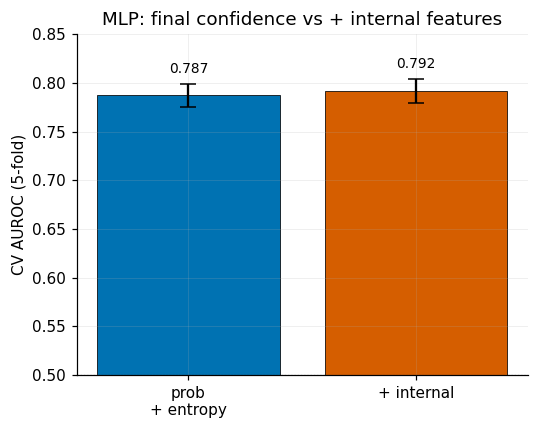

In [ ]:
labels = ["prob\n+ entropy", "+ internal"]
means  = [m_conf, m_conf_int]
stds   = [s_conf, s_conf_int]

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(labels, means, yerr=stds, capsize=5,
              color=[C_OK, C_ERR], edgecolor="black", linewidth=0.5)
ax.set_ylabel("CV AUROC (5-fold)")
ax.set_title("MLP: final confidence vs + internal features")
ax.set_ylim(0.5, 0.85)
ax.axhline(0.5, color="grey", lw=0.8, ls=":")
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width()/2, m + 0.02, f"{m:.3f}",
            ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.show()

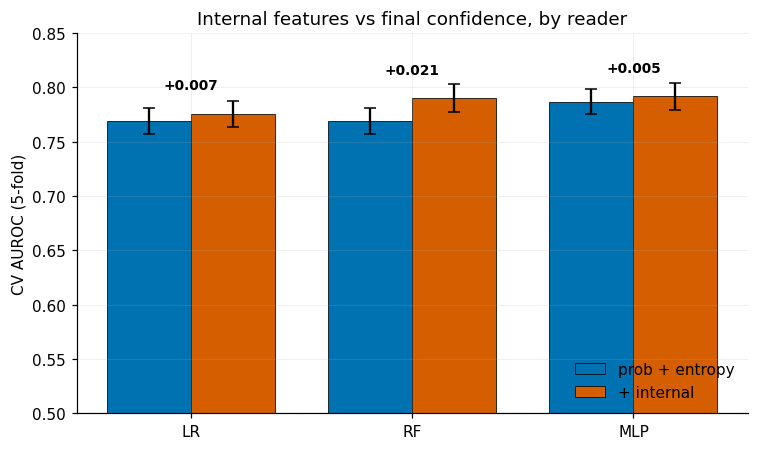

In [54]:
import numpy as np

readers = ["LR", "RF", "MLP"]

# fill from your runs: (baseline_mean, baseline_std, internal_mean, internal_std)
results = {
    "LR":  (0.769, 0.012, 0.776, 0.012),   # LR: +0.007
    "RF":  (0.769, 0.012, 0.790, 0.013),   # RF: +0.021
    "MLP": (m_conf, s_conf, m_conf_int, s_conf_int),   # MLP: still in memory from last cell
}

base_m = [results[r][0] for r in readers]
base_s = [results[r][1] for r in readers]
int_m  = [results[r][2] for r in readers]
int_s  = [results[r][3] for r in readers]

x = np.arange(len(readers))
w = 0.38

fig, ax = plt.subplots(figsize=(7, 4.2))
b1 = ax.bar(x - w/2, base_m, w, yerr=base_s, capsize=4,
            color=C_OK,  edgecolor="black", linewidth=0.5, label="prob + entropy")
b2 = ax.bar(x + w/2, int_m,  w, yerr=int_s,  capsize=4,
            color=C_ERR, edgecolor="black", linewidth=0.5, label="+ internal")

ax.set_xticks(x, readers)
ax.set_ylabel("CV AUROC (5-fold)")
ax.set_title("Internal features vs final confidence, by reader")
ax.set_ylim(0.5, 0.85)                       # shared honest axis, AUROC floor
ax.axhline(0.5, color="grey", lw=0.8, ls=":")
ax.legend(frameon=False, loc="lower right")

# annotate the gain above each pair
for i, r in enumerate(readers):
    g = int_m[i] - base_m[i]
    ax.text(i, max(base_m[i], int_m[i]) + 0.02, f"+{g:.3f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

fig.tight_layout()
plt.show()